In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *


In [4]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']

colors = np.array([[0.8, 0.3, 0.7],
       [0.8, 0.5, 0.3],
       [0.5, 0.8, 0.3],
       [0.3, 0.8, 0.7],
       [0.3, 0.3, 0.8]])

load_path = project_folder + '/analyses/cross-stim performance/saved/hold_one_out_4_repeats_16_iter.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [5]:
data.mi_average_test

array([[0.41260688, 0.3454535 ],
       [0.15188781, 0.13697428],
       [0.5104477 , 0.4201227 ],
       [0.61954627, 0.50450649],
       [0.89391276, 0.68799286]])

In [11]:
I_normed = data.mi_average_test / np.diag(data.mi_average_test)[None,:]
I = data.mi_average_test / np.log(2)
I_err = data.mi_stdevs_test / np.log(2)
I_ctl = I[:,0]
I_nov = I[:,1]
I_ctl_err = I_err[:,0]
I_nov_err = I_err[:,1]

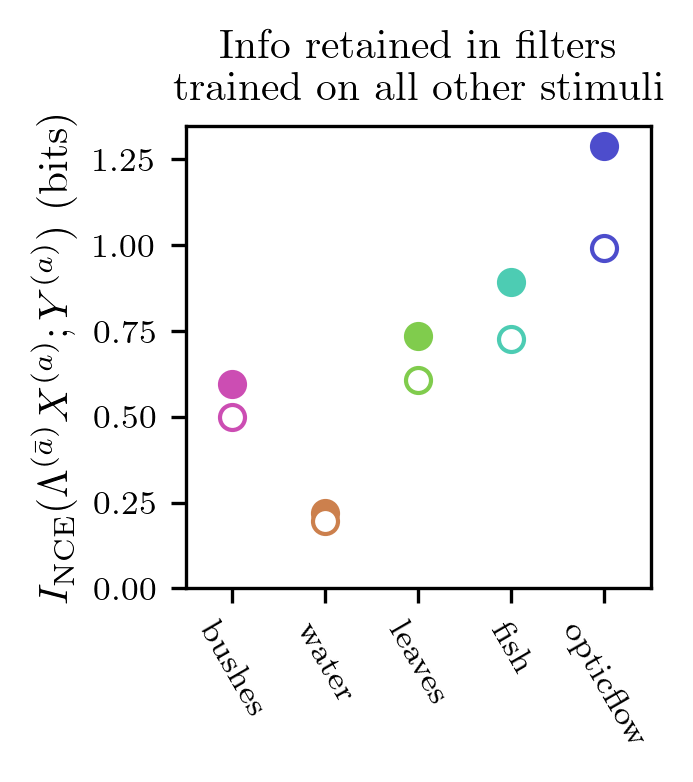

In [46]:
alp = 0.1
margin = 0.5
# plot_scale = 0.7
plot_scale = 0.5
g=1

fig, ax = plt.subplots(figsize=[4*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    x = j
    y = I_ctl[j]
    y_err = I_ctl_err[j]
    ax.errorbar(x, y, y_err, marker='o', color=colors[j])

    y = I_nov[j]
    y_err = I_nov_err[j]
    ax.errorbar(x, y, y_err, marker='o', color=(g,g,g), linestyle='', markeredgecolor=colors[j])


# ax.errorbar([],[], marker='o', color=colors[0], label='trained, tested on bushes')
# ax.errorbar([],[], marker='o', color=colors[0], markeredgecolor=colors[1], label='trained on bushes, tested on water')
# ax.legend()

ax.set_ylim(0)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
# ax.set_yticks([0,1])
ax.set_ylabel("$I_{\mathrm{NCE}}(\Lambda^{(\\bar{a})}X^{(a)};Y^{(a)})$ (bits)")
ax.set_title("Info retained in filters\n trained on all other stimuli")    
# fig.savefig('./plots/compressibility across stim.svg', bbox_inches="tight")
fig.savefig('./plots/hold_one_out_left.png', dpi=3000)

In [ ]:
# copied from cross-stim pairwise.ipynb
I_pairwise_nov_avg = np.array([0.48528401, 0.19555662, 0.59929784, 0.70972868, 0.97921816])
I_pairwise_nov_stdevs = np.array([0.00136078, 0.00122712, 0.00515443, 0.00134105, 0.00386072])

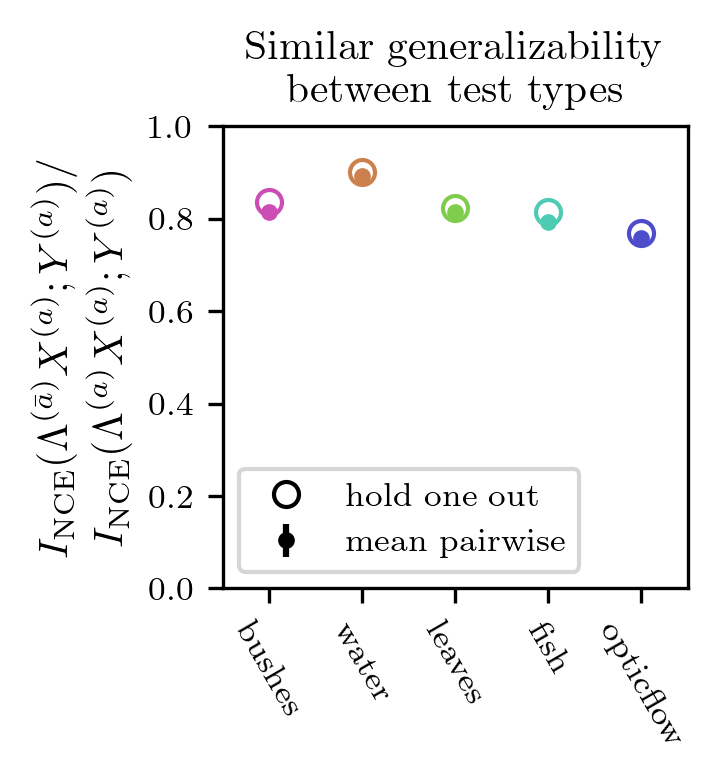

In [47]:
alp = 0.1
margin = 0.5
# plot_scale = 0.7
plot_scale = 0.5
w = 0.3

fig, ax = plt.subplots(figsize=[4*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    # y = I[j,j]
    # y_err = I_err[j,j]
    # ax.errorbar(x, y, y_err, marker='o', color=colors[j])

    x = j
    y = I_nov[j] / I_ctl[j]
    y_err = I_nov_err[j] / I_ctl[j]
    ax.errorbar(x, y, y_err, marker='o', color=(g,g,g), linestyle='', markeredgecolor=colors[j])
    # ax.axhline(I_pairwise_nov_avg[j] / I_ctl[j], color=colors[j], linestyle=':',zorder=-1)
    ax.errorbar(x, I_pairwise_nov_avg[j] / I_ctl[j], I_pairwise_nov_stdevs[j] / I_ctl[j], marker='.', color=colors[j], zorder=10)

ax.errorbar([],[], [],marker='o', linestyle='', label='hold one out', color=(g,g,g), markeredgecolor='k')
ax.errorbar([],[], [],marker='.', linestyle='', label='mean pairwise', color='k')

# ax.errorbar([],[], marker='o', color=colors[0], label='trained, tested on bushes')
# ax.errorbar([],[], marker='o', color=colors[0], markeredgecolor=colors[1], label='trained on bushes, tested on water')
# ax.legend()

ax.legend()

ax.set_ylim(0, 1)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
# ax.set_yticks([0,1])
ax.set_ylabel("$I_{\mathrm{NCE}}(\Lambda^{(\\bar{a})}X^{(a)};Y^{(a)}) /$\n $I_{\mathrm{NCE}}(\Lambda^{(a)}X^{(a)};Y^{(a)})$")
ax.set_title("Similar generalizability \n between test types")    
fig.savefig('./plots/hold_one_out_right.png', dpi=3000)